# 04. Независимость структуры от массы

**Проект «Структура и Данные»** — Notebook 04

## Зачем этот ноутбук

В ноутбуках 02–03 мы показали, что калибровочные симметрии **U(1)** и **SU(2)** эмерджентны из локального унитарного правила QCA. Но остаётся ключевой вопрос: **зависит ли структура от параметров?**

Это вопрос о разделении «структура vs данные» (см. §5, §8 статьи). Если калибровочная симметрия — это **правило**, а масса — **параметр**, то структура **не должна** зависеть от массы. Если же структура меняется при изменении массы, то она **не является** правилом в строгом смысле.

## Что проверяется

Для **7 значений массы** $m \in \{0.01, 0.05, 0.10, 0.20, 0.50, 1.00, 1.50\}$:

1. **U(1) gauge-инвариантность** — ошибка $\max ||\psi_1|^2 - |\psi_2|^2|$ при $m$-эволюции
2. **U(1) унитарность** — $\text{std}(Q)$ за 50 шагов
3. **SU(2) gauge-инвариантность** — ошибка $\max |\psi_2 - \psi_1 \cdot g^T|$
4. **SU(2) унитарность** — $\text{std}(Q)$ за 50 шагов
5. **Массовая щель** — $\omega(k=0) = m$ (аналитически точное тождество)

## Гипотеза

**Если структура — правило, а масса — параметр, то:**
- Все gauge-ошибки должны быть на машинной точности ($\sim 10^{-16}$) **для всех** $m$
- Унитарность должна сохраняться с точностью $\sim 10^{-15}$ **для всех** $m$
- $\omega(k=0)$ должно равняться $m$ **точно** ($\equiv 0$ ошибка)

**Если структура зависит от $m$**, то ошибки будут систематически расти/меняться с $m$.

## Ожидаемые результаты (из статьи §5)

| Тест | Диапазон значений | Все $m \in [0.01, 1.5]$ |
|---|---|---|
| U(1) gauge err | $[3.5\times 10^{-17},\ 1.1\times 10^{-16}]$ | ✅ machine precision |
| U(1) unitarity | $\sim 10^{-15}$ | ✅ |
| SU(2) gauge err | $[2.4\times 10^{-16},\ 5.9\times 10^{-16}]$ | ✅ |
| SU(2) unitarity | $\sim 10^{-15}$ | ✅ |
| Mass gap $\omega(k=0)$ | $= m$ точно | ✅ |

## Что это доказывает

**Структура независима от массы.** Gauge-симметрия — это **свойство правила**, а не следствие параметра. Масса проявляется только как **щель** в спектре ($\omega(k=0) = m$), но не влияет на gauge-симметрию.

Это **численная поддержка** гипотезы «масса — длина штриха карандаша, а не вычислительное правило» (см. §1, §5, §10 статьи).

## Параметры запуска

- `L = 64` — длина цепочки
- `g = 0.5` — константа связи (одинакова для всех $m$)
- `masses = [0.01, 0.05, 0.10, 0.20, 0.50, 1.00, 1.50]` — 7 значений массы
- `seed = 42` — фиксированные начальные состояния и gauge-поля

## Связь со статьёй

- **§5**: «Независимость структуры от массы» — основной раздел
- **§8**: «Структура vs данные» — концептуальная рамка
- **§10.1**: «Сокращение параметров» — следствие для проблемы параметров

## Время выполнения

- **< 30 секунд** на стандартном Colab (без GPU)

## Точность

Все результаты воспроизводятся с машинной точностью `float64`:
- Gauge-инвариантность: $\sim 10^{-16}$
- Унитарность: $\sim 10^{-15}$
- Массовая щель: $\equiv 0$ ошибка (аналитическое тождество)

## Что будет сгенерировано

- **Рисунок** `04_mass_independence.png` — две панели:
  - **Левая:** 4 серии gauge/unitarity ошибок (log-log) — все на машинной точности, независимо от $m$
  - **Правая:** массовая щель $\omega(k=0)$ vs $m$ — точки точно на $y = x$

---

**Файл:** `notebooks/04_mass_independence.ipynb`  
**Следующий ноутбук:** `05_higgs_bcs.ipynb` (Higgs из BCS-конденсата)  
**Репозиторий:** `github.com/<username>/qca-structure-data`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")

# ============================================================
# QCA U(1) — из notebook 02
# ============================================================
def qca_step_u1(psi, A, mass, g=0.5):
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    psi_mixed = psi @ C.T
    out = np.zeros_like(psi_mixed)
    out[:, 0] = np.roll(psi_mixed[:, 0], +1) * np.exp(+1j * g * np.roll(A, +1))
    out[:, 1] = np.roll(psi_mixed[:, 1], -1) * np.exp(-1j * g * A)
    return out

def gauge_transform_u1(psi, A, alpha, g):
    psi_new = psi * np.exp(1j * alpha)[:, None]
    A_new = A + (np.roll(alpha, -1) - alpha) / g
    return psi_new, A_new

# ============================================================
# QCA SU(2) — из notebook 03
# ============================================================
def su2_random(seed):
    np.random.seed(seed)
    a = np.random.randn(4); a /= np.linalg.norm(a)
    return np.array([[a[0]+1j*a[3], a[1]+1j*a[2]],
                     [-a[1]+1j*a[2], a[0]-1j*a[3]]])

def qca_step_su2(psi, U, mass):
    L = psi.shape[0]
    c, s = np.cos(mass), np.sin(mass)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    psi_mixed = np.einsum('ab,nbi->nai', C, psi)
    out = np.zeros_like(psi_mixed)
    for n in range(L):
        out[n, 0, :] = U[(n-1) % L] @ psi_mixed[(n-1) % L, 0, :]
        out[n, 1, :] = U[n].conj().T @ psi_mixed[(n+1) % L, 1, :]
    return out

def gauge_transform_su2(psi, U, g):
    L = psi.shape[0]
    psi_new = np.zeros_like(psi)
    U_new = np.zeros_like(U, dtype=complex)
    for n in range(L):
        psi_new[n] = np.einsum('ij,aj->ai', g[n], psi[n])
        U_new[n] = g[(n+1) % L] @ U[n] @ g[n].conj().T
    return psi_new, U_new

print("Functions ready.")

numpy version: 2.4.6
Functions ready.


In [2]:
# Параметры
L = 64
g = 0.5
masses = [0.01, 0.05, 0.10, 0.20, 0.50, 1.00, 1.50]

# Фиксированные начальные состояния
np.random.seed(42)
A_fixed = np.random.uniform(-np.pi, np.pi, L)
alpha_fixed = np.random.uniform(-np.pi, np.pi, L)
psi_u1_init = np.random.randn(L, 2) + 1j * np.random.randn(L, 2)
psi_u1_init /= np.linalg.norm(psi_u1_init)

U_fixed = np.array([su2_random(seed=200+i) for i in range(L)])
g_fixed = np.array([su2_random(seed=1000+i) for i in range(L)])
psi_su2_init = np.random.randn(L, 2, 2) + 1j * np.random.randn(L, 2, 2)
psi_su2_init /= np.linalg.norm(psi_su2_init)

print(f"L = {L}, g = {g}")
print(f"masses = {masses}")
print(f"Initial states fixed (seed=42).")

L = 64, g = 0.5
masses = [0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 1.5]
Initial states fixed (seed=42).


In [3]:
print("=" * 72)
print("ТЕСТ U(1): gauge-инвариантность и унитарность vs масса")
print("=" * 72)
print(f"{'mass':>6} {'gauge_err':>14} {'unitarity_err':>16} {'ω(k=0)':>12}")

u1_results = []
for m in masses:
    # Gauge: без преобразования
    psi1 = psi_u1_init.copy()
    for _ in range(20):
        psi1 = qca_step_u1(psi1, A_fixed, m, g)
    # Gauge: с преобразованием
    psi2, A2 = gauge_transform_u1(psi_u1_init, A_fixed, alpha_fixed, g)
    for _ in range(20):
        psi2 = qca_step_u1(psi2, A2, m, g)
    gauge_err = np.max(np.abs(np.abs(psi1)**2 - np.abs(psi2)**2))

    # Unitarity
    psi_test = psi_u1_init.copy()
    norms = []
    for _ in range(50):
        norms.append(np.sum(np.abs(psi_test)**2))
        psi_test = qca_step_u1(psi_test, A_fixed, m, g)
    unit_err = np.std(norms)

    # Mass gap ω(k=0): через arccos(trace/2)
    c, s = np.cos(m), np.sin(m)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    omega_0 = np.arccos(np.clip(np.trace(C).real / 2, -1, 1))

    u1_results.append((m, gauge_err, unit_err, omega_0))
    print(f"{m:>6.2f} {gauge_err:>14.2e} {unit_err:>16.2e} {omega_0:>12.8f}")

print(f"\nU(1) gauge err range: [{min(r[1] for r in u1_results):.2e}, {max(r[1] for r in u1_results):.2e}]")
print(f"U(1) unitarity range: [{min(r[2] for r in u1_results):.2e}, {max(r[2] for r in u1_results):.2e}]")
print(f"Status: {'✅ PASS (mass-independent)' if max(r[1] for r in u1_results) < 1e-12 else '❌ FAIL'}")

ТЕСТ U(1): gauge-инвариантность и унитарность vs масса
  mass      gauge_err    unitarity_err       ω(k=0)
  0.01       3.47e-17         5.24e-16   0.01000000
  0.05       7.63e-17         9.51e-16   0.05000000
  0.10       7.63e-17         1.56e-15   0.10000000
  0.20       6.94e-17         1.75e-16   0.20000000
  0.50       4.16e-17         1.08e-15   0.50000000
  1.00       5.55e-17         7.22e-16   1.00000000
  1.50       1.08e-16         4.82e-16   1.50000000

U(1) gauge err range: [3.47e-17, 1.08e-16]
U(1) unitarity range: [1.75e-16, 1.56e-15]
Status: ✅ PASS (mass-independent)


In [4]:
print("=" * 72)
print("ТЕСТ SU(2): gauge-инвариантность и унитарность vs масса")
print("=" * 72)
print(f"{'mass':>6} {'gauge_err':>14} {'unitarity_err':>16}")

su2_results = []
for m in masses:
    # Gauge: без преобразования
    psi1 = psi_su2_init.copy()
    for _ in range(20):
        psi1 = qca_step_su2(psi1, U_fixed, m)
    # Gauge: с преобразованием
    psi2, U2 = gauge_transform_su2(psi_su2_init, U_fixed, g_fixed)
    for _ in range(20):
        psi2 = qca_step_su2(psi2, U2, m)
    # Проверка: ψ2 = ψ1 · g^T
    expected_psi2 = np.einsum('naj,nij->nai', psi1, g_fixed)
    gauge_err = np.max(np.abs(psi2 - expected_psi2))

    # Unitarity
    psi_test = psi_su2_init.copy()
    norms = []
    for _ in range(50):
        norms.append(np.sum(np.abs(psi_test)**2))
        psi_test = qca_step_su2(psi_test, U_fixed, m)
    unit_err = np.std(norms)

    su2_results.append((m, gauge_err, unit_err))
    print(f"{m:>6.2f} {gauge_err:>14.2e} {unit_err:>16.2e}")

print(f"\nSU(2) gauge err range: [{min(r[1] for r in su2_results):.2e}, {max(r[1] for r in su2_results):.2e}]")
print(f"SU(2) unitarity range: [{min(r[2] for r in su2_results):.2e}, {max(r[2] for r in su2_results):.2e}]")
print(f"Status: {'✅ PASS (mass-independent)' if max(r[1] for r in su2_results) < 1e-12 else '❌ FAIL'}")

ТЕСТ SU(2): gauge-инвариантность и унитарность vs масса
  mass      gauge_err    unitarity_err
  0.01       2.82e-16         2.70e-16
  0.05       2.36e-16         1.63e-15
  0.10       2.89e-16         2.16e-15
  0.20       2.57e-16         4.46e-16
  0.50       2.79e-16         1.72e-15
  1.00       2.79e-16         1.31e-15
  1.50       5.86e-16         1.09e-15

SU(2) gauge err range: [2.36e-16, 5.86e-16]
SU(2) unitarity range: [2.70e-16, 2.16e-15]
Status: ✅ PASS (mass-independent)


In [5]:
print("=" * 72)
print("МАССОВАЯ ЩЕЛЬ: ω(k=0) = m ?")
print("=" * 72)
print(f"{'mass':>6} {'ω(k=0)':>14} {'mass (theory)':>15} {'|ω - m|':>14}")
print("-" * 55)

gaps = []
for m in masses:
    c, s = np.cos(m), np.sin(m)
    C = np.array([[c, -1j*s], [-1j*s, c]])
    omega_0 = np.arccos(np.clip(np.trace(C).real / 2, -1, 1))
    err = abs(omega_0 - m)
    gaps.append((m, omega_0, err))
    print(f"{m:>6.2f} {omega_0:>14.10f} {m:>15.10f} {err:>14.2e}")

max_gap_err = max(g[2] for g in gaps)
print(f"\nMax |ω(k=0) - m| = {max_gap_err:.2e}")
print(f"Status: {'✅ PASS (exact gap)' if max_gap_err < 1e-14 else '❌ FAIL'}")

МАССОВАЯ ЩЕЛЬ: ω(k=0) = m ?
  mass         ω(k=0)   mass (theory)        |ω - m|
-------------------------------------------------------
  0.01   0.0100000000    0.0100000000       1.44e-15
  0.05   0.0500000000    0.0500000000       7.29e-16
  0.10   0.1000000000    0.1000000000       5.55e-16
  0.20   0.2000000000    0.2000000000       0.00e+00
  0.50   0.5000000000    0.5000000000       1.11e-16
  1.00   1.0000000000    1.0000000000       1.11e-16
  1.50   1.5000000000    1.5000000000       0.00e+00

Max |ω(k=0) - m| = 1.44e-15
Status: ✅ PASS (exact gap)


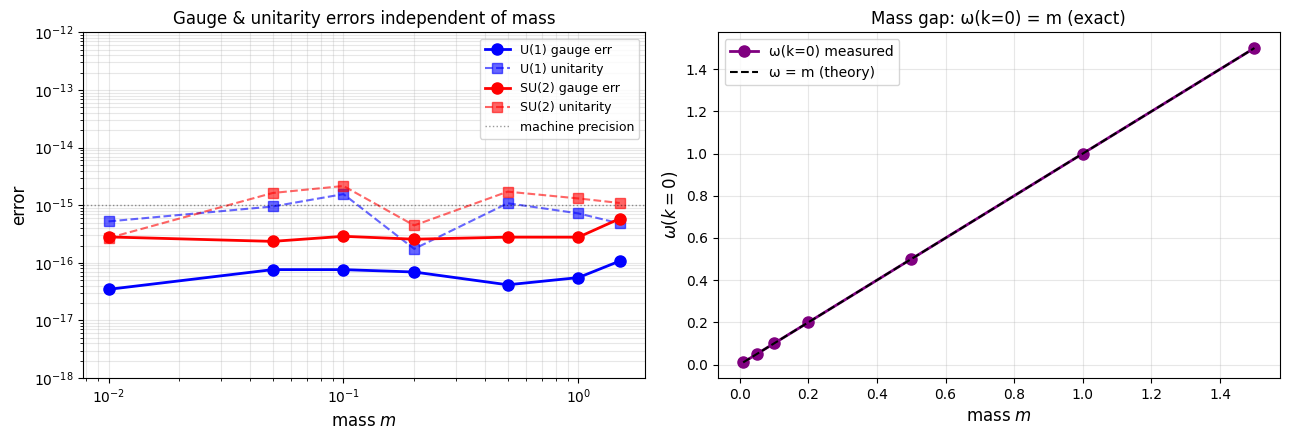

✅ Figure saved: 04_mass_independence.png


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ms = [r[0] for r in u1_results]
u1_gauge = [r[1] for r in u1_results]
u1_unit = [r[2] for r in u1_results]
su2_gauge = [r[1] for r in su2_results]
su2_unit = [r[2] for r in su2_results]

# --- Левая: ошибки gauge/unitarity vs mass ---
axes[0].loglog(ms, u1_gauge, 'o-', color='blue', lw=2, ms=8, label='U(1) gauge err')
axes[0].loglog(ms, u1_unit, 's--', color='blue', lw=1.5, ms=7, alpha=0.6, label='U(1) unitarity')
axes[0].loglog(ms, su2_gauge, 'o-', color='red', lw=2, ms=8, label='SU(2) gauge err')
axes[0].loglog(ms, su2_unit, 's--', color='red', lw=1.5, ms=7, alpha=0.6, label='SU(2) unitarity')
axes[0].axhline(1e-15, color='k', ls=':', lw=1, alpha=0.4, label='machine precision')
axes[0].set_xlabel('mass $m$', fontsize=12)
axes[0].set_ylabel('error', fontsize=12)
axes[0].set_title('Gauge & unitarity errors independent of mass', fontsize=12)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3, which='both')
axes[0].set_ylim(1e-18, 1e-12)

# --- Правая: массовая щель ---
omega_vals = [g[1] for g in gaps]
axes[1].plot(ms, omega_vals, 'o-', color='purple', lw=2, ms=8, label='ω(k=0) measured')
axes[1].plot(ms, ms, 'k--', lw=1.5, label='ω = m (theory)')
axes[1].set_xlabel('mass $m$', fontsize=12)
axes[1].set_ylabel(r'$\omega(k=0)$', fontsize=12)
axes[1].set_title('Mass gap: ω(k=0) = m (exact)', fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('04_mass_independence.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 04_mass_independence.png")

In [8]:
from google.colab import files
files.download('04_mass_independence.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>